In [ ]:

# Imports & Setup
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

from sklearn.model_selection import train_test_split
from sklearn.preprocessing import StandardScaler
from sklearn.linear_model import LinearRegression
from sklearn.ensemble import RandomForestRegressor
from sklearn.tree import DecisionTreeRegressor
from sklearn.metrics import mean_absolute_error, mean_squared_error, r2_score

pd.set_option('display.max_columns', None)
pd.set_option('display.width', 140)
sns.set_style("whitegrid")
np.random.seed(42)
print("Imports OK")

Imports OK


In [3]:
#Load & Inspect
retail = pd.read_csv('Retail_stores.csv')
print("Shape:", retail.shape)
print("\nColumns:", retail.columns.tolist())
print("\nData types:\n", retail.dtypes)
retail.head()

Shape: (5100, 14)

Columns: ['StoreID', 'Region', 'StoreType', 'MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours', 'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales', 'Season', 'SalesRevenue']

Data types:
 StoreID                    int64
Region                       str
StoreType                    str
MarketingSpend           float64
Footfall                 float64
OnlineTraffic            float64
StaffHours               float64
DiscountRate             float64
CustomerSatisfaction     float64
InventoryAvailability    float64
CompetitorDistance       float64
PreviousMonthSales       float64
Season                       str
SalesRevenue             float64
dtype: object


,StoreID,Region,StoreType,MarketingSpend,Footfall,OnlineTraffic,StaffHours,DiscountRate,CustomerSatisfaction,InventoryAvailability,CompetitorDistance,PreviousMonthSales,Season,SalesRevenue
0,1051,North,Mall,3112.970133,1194.757278,5995.253123,295.914621,19.067494,NaN,81.001043,12.969511,50135.817486,Summer,249522.51
1,1092,North,Town,6318.707486,1893.939723,9399.307313,303.880533,4.222433,59.670866,83.521835,17.890113,46881.417221,Winter,362564.72
2,1014,North,Retail Park,4934.112301,1280.261621,13337.943755,347.676004,4.259883,76.553271,95.342429,19.873263,50382.031910,Winter,315300.65
3,1071,North,Town,6631.180326,728.987814,6510.314785,337.097053,38.564438,85.944732,90.215647,11.560488,48063.975734,Winter,360506.70
4,1060,South,Town,5262.867791,602.074362,10394.071431,327.638120,39.174709,67.329625,76.199892,7.291224,44882.500605,Autumn,323011.58


=== MISSING VALUES ===
                       MissingCount  MissingPct
InventoryAvailability           358        7.02
OnlineTraffic                   355        6.96
MarketingSpend                  353        6.92
CustomerSatisfaction            352        6.90


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\319598595.py:11: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=missing.index, y=missing['MissingPct'], palette='Reds_r')


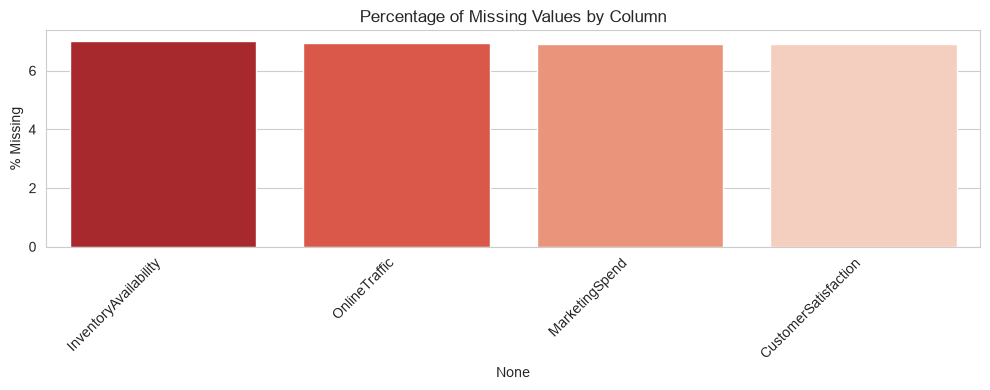

In [4]:
missing = pd.DataFrame({
    'MissingCount': retail.isnull().sum(),
    'MissingPct': (retail.isnull().sum() / len(retail) * 100).round(2)
})
missing = missing[missing['MissingCount'] > 0].sort_values('MissingPct', ascending=False)
print("=== MISSING VALUES ===")
print(missing)

if len(missing) > 0:
    plt.figure(figsize=(10, 4))
    sns.barplot(x=missing.index, y=missing['MissingPct'], palette='Reds_r')
    plt.title('Percentage of Missing Values by Column')
    plt.ylabel('% Missing')
    plt.xticks(rotation=45, ha='right')
    plt.tight_layout()
    plt.show()

In [5]:
print("=== DUPLICATES ===")
print(f"Full duplicate rows: {retail.duplicated().sum()}")
print(f"Repeated StoreIDs:   {retail['StoreID'].duplicated().sum()}")
print(f"Unique StoreIDs:     {retail['StoreID'].nunique()}")

business_key = ['StoreID', 'Season', 'Region']
dup_business = retail.duplicated(subset=business_key).sum()
print(f"Duplicates on business key {business_key}: {dup_business}")

=== DUPLICATES ===
Full duplicate rows: 100
Repeated StoreIDs:   5000
Unique StoreIDs:     100
Duplicates on business key ['StoreID', 'Season', 'Region']: 3575


In [6]:
numeric_cols = [c for c in retail.select_dtypes(include=np.number).columns if c != 'StoreID']

outlier_summary = []
for col in numeric_cols:
    s = retail[col].dropna()
    q1, q3 = s.quantile(0.25), s.quantile(0.75)
    iqr = q3 - q1
    lower, upper = q1 - 1.5*iqr, q3 + 1.5*iqr
    n_out = ((s < lower) | (s > upper)).sum()
    outlier_summary.append({
        'Column': col, 'Q1': round(q1,2), 'Q3': round(q3,2),
        'Lower': round(lower,2), 'Upper': round(upper,2),
        'Outliers': n_out, 'OutlierPct': round(n_out/len(s)*100, 2)
    })

outliers = pd.DataFrame(outlier_summary).sort_values('OutlierPct', ascending=False)
print("=== OUTLIER SUMMARY (IQR) ===")
print(outliers.to_string(index=False))

=== OUTLIER SUMMARY (IQR) ===
               Column        Q1        Q3     Lower     Upper  Outliers  OutlierPct
       MarketingSpend   3976.51   6059.86    851.48   9184.88        71        1.50
         SalesRevenue 285897.32 348445.68 192074.78 442268.22        72        1.41
             Footfall    964.95   1444.26    245.99   2163.23        38        0.75
   PreviousMonthSales  38768.14  50937.01  20514.84  69190.31        30        0.59
        OnlineTraffic   6850.05  10247.97   1753.18  15344.85        26        0.55
           StaffHours    293.49    403.38    128.65    568.22        26        0.51
 CustomerSatisfaction     68.19     81.67     47.96    101.90        13        0.27
InventoryAvailability     79.48     90.54     62.90    107.13         9        0.19
         DiscountRate     10.06     29.90    -19.70     59.66         0        0.00
   CompetitorDistance      5.50     15.24     -9.11     29.85         0        0.00


In [7]:
retail_clean = retail.copy()
print("Missing BEFORE:", retail_clean.isnull().sum().sum())

# Median imputation for skewed numeric features
for col in ['MarketingSpend', 'CustomerSatisfaction', 'OnlineTraffic', 'InventoryAvailability']:
    if col in retail_clean.columns:
        med = retail_clean[col].median()
        retail_clean[col] = retail_clean[col].fillna(med)
        print(f"Filled {col} with median = {med:.2f}")

# Drop true duplicates only
before = len(retail_clean)
retail_clean = retail_clean.drop_duplicates(subset=['StoreID','Season','Region'], keep='first')
print(f"\nDuplicates removed: {before - len(retail_clean)}")

# Winsorise MarketingSpend at 99th percentile
cap_99 = retail_clean['MarketingSpend'].quantile(0.99)
n_capped = (retail_clean['MarketingSpend'] > cap_99).sum()
retail_clean['MarketingSpend'] = retail_clean['MarketingSpend'].clip(upper=cap_99)
print(f"MarketingSpend capped at {cap_99:.2f}; records affected: {n_capped}")

print("\nMissing AFTER:", retail_clean.isnull().sum().sum())
print("Final shape:", retail_clean.shape)

Missing BEFORE: 1418
Filled MarketingSpend with median = 5002.19
Filled CustomerSatisfaction with median = 74.74
Filled OnlineTraffic with median = 8498.92
Filled InventoryAvailability with median = 85.01

Duplicates removed: 3575
MarketingSpend capped at 24472.32; records affected: 16

Missing AFTER: 0
Final shape: (1525, 14)


In [8]:
retail_clean['MarketingEfficiency'] = retail_clean['SalesRevenue'] / retail_clean['MarketingSpend'].replace(0, np.nan)
retail_clean['RevenuePerFootfall']  = retail_clean['SalesRevenue'] / retail_clean['Footfall'].replace(0, np.nan)
retail_clean['OnlineShare']         = retail_clean['OnlineTraffic'] / (retail_clean['OnlineTraffic'] + retail_clean['Footfall']).replace(0, np.nan)
retail_clean['RevenueGrowth']       = (retail_clean['SalesRevenue'] - retail_clean['PreviousMonthSales']) / retail_clean['PreviousMonthSales'].replace(0, np.nan)
retail_clean['SalesPerStaffHour']   = retail_clean['SalesRevenue'] / retail_clean['StaffHours'].replace(0, np.nan)
retail_clean['IsPeakSeason']        = retail_clean['Season'].isin(['Summer','Winter']).astype(int)

new_cols = ['MarketingEfficiency','RevenuePerFootfall','OnlineShare',
            'RevenueGrowth','SalesPerStaffHour','IsPeakSeason']
print("Engineered features summary:")
print(retail_clean[new_cols].describe().T.round(3))

Engineered features summary:
                      count     mean      std      min      25%      50%       75%       max
MarketingEfficiency  1525.0   66.654   19.699   10.146   57.610   63.676    72.273   397.617
RevenuePerFootfall   1525.0  293.400  157.862   80.277  212.468  259.184   329.099  2961.334
OnlineShare          1525.0    0.868    0.057    0.272    0.844    0.875     0.903     0.990
RevenueGrowth        1525.0    6.295    2.066    1.098    4.963    5.984     7.276    22.787
SalesPerStaffHour    1525.0  952.493  313.729  210.011  752.277  900.435  1094.105  3858.888
IsPeakSeason         1525.0    0.497    0.500    0.000    0.000    0.000     1.000     1.000


In [10]:
print("="*60)
print("FINAL DATA QUALITY SUMMARY – Retail_stores.csv")
print("="*60)
print(f"Original rows:         {len(retail)}")
print(f"Cleaned rows:          {len(retail_clean)}")
print(f"Columns originally:    {retail.shape[1]}")
print(f"Columns after FE:      {retail_clean.shape[1]}")
print(f"Missing before:        {retail.isnull().sum().sum()}")
print(f"Missing after:         {retail_clean.isnull().sum().sum()}")
print(f"Duplicates removed:    {len(retail) - len(retail_clean)}")
print(f"Outliers capped:       {n_capped} (MarketingSpend @ 99th pct)")
print("\nEngineered features:", new_cols)

retail_clean.to_csv('retail_clean.csv', index=False)
print("\n Saved to retail_clean.csv")

FINAL DATA QUALITY SUMMARY – Retail_stores.csv
Original rows:         5100
Cleaned rows:          1525
Columns originally:    14
Columns after FE:      20
Missing before:        1418
Missing after:         0
Duplicates removed:    3575
Outliers capped:       16 (MarketingSpend @ 99th pct)

Engineered features: ['MarketingEfficiency', 'RevenuePerFootfall', 'OnlineShare', 'RevenueGrowth', 'SalesPerStaffHour', 'IsPeakSeason']

 Saved to retail_clean.csv


=== SUMMARY STATISTICS (key metrics) ===
       SalesRevenue  MarketingSpend  Footfall  OnlineTraffic  CustomerSatisfaction  DiscountRate
count       1525.00         1525.00   1525.00        1525.00               1525.00       1525.00
mean      314792.71         5223.16   1208.95        8567.80                 74.93         20.25
std        48731.01         2579.70    350.45        2450.59                  9.54         11.40
min        92957.26          250.00    100.00         500.00                 39.78          0.01
25%       284442.43         4021.57    971.84        6956.23                 68.92         10.21
50%       318310.47         5002.19   1214.55        8498.92                 74.74         20.23
75%       349155.94         5980.22   1450.71       10029.42                 81.01         29.92
max       465006.45        24472.32   2384.59       18016.79                100.00         39.97


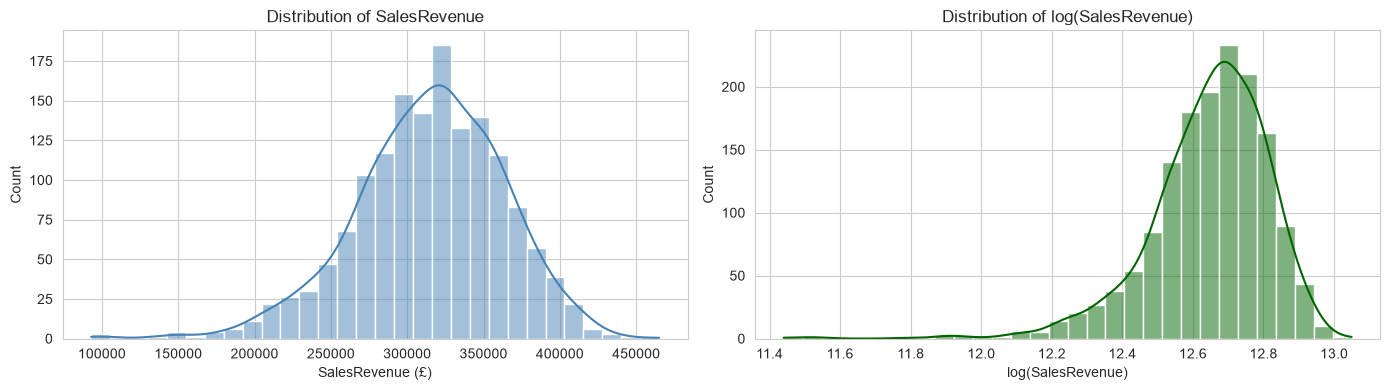

In [11]:
print("=== SUMMARY STATISTICS (key metrics) ===")
print(retail_clean[['SalesRevenue','MarketingSpend','Footfall',
                     'OnlineTraffic','CustomerSatisfaction','DiscountRate']].describe().round(2))

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.histplot(retail_clean['SalesRevenue'], bins=30, kde=True, ax=axes[0], color='steelblue')
axes[0].set_title('Distribution of SalesRevenue')
axes[0].set_xlabel('SalesRevenue (£)')

sns.histplot(np.log1p(retail_clean['SalesRevenue']), bins=30, kde=True, ax=axes[1], color='darkgreen')
axes[1].set_title('Distribution of log(SalesRevenue)')
axes[1].set_xlabel('log(SalesRevenue)')
plt.tight_layout()
plt.show()

=== GROUPBY 1: Revenue by Region ===
        TotalRevenue  AvgRevenue  AvgMarketingSpend  AvgFootfall  N_Records
Region                                                                     
North   1.210960e+08   312909.45            5193.99      1203.97        387
West    1.208470e+08   317183.70            5386.62      1226.48        381
South   1.202820e+08   314052.18            5167.78      1198.94        383
East    1.178340e+08   315064.07            5143.54      1206.51        374


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\3786424507.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=region_stats.index, y=region_stats['AvgRevenue'], ax=ax, palette='Blues_d')


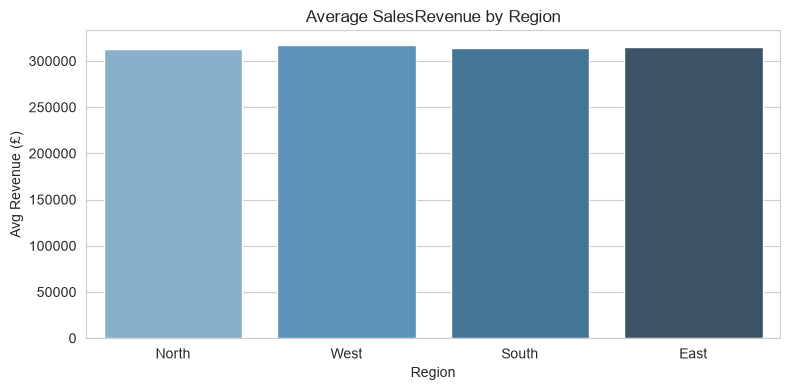

In [12]:
region_stats = retail_clean.groupby('Region').agg(
    TotalRevenue=('SalesRevenue','sum'),
    AvgRevenue=('SalesRevenue','mean'),
    AvgMarketingSpend=('MarketingSpend','mean'),
    AvgFootfall=('Footfall','mean'),
    N_Records=('SalesRevenue','count')
).round(2).sort_values('TotalRevenue', ascending=False)

print("=== GROUPBY 1: Revenue by Region ===")
print(region_stats)

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=region_stats.index, y=region_stats['AvgRevenue'], ax=ax, palette='Blues_d')
ax.set_title('Average SalesRevenue by Region')
ax.set_ylabel('Avg Revenue (£)')
plt.tight_layout()
plt.show()

=== GROUPBY 2: Revenue by Store Type ===
             TotalRevenue  AvgRevenue  AvgFootfall  AvgOnlineTraffic  AvgSatisfaction  N_Records
StoreType                                                                                       
Mall         1.629647e+08   317670.04      1202.91           8715.96            74.70        513
Town         1.642852e+08   313521.35      1230.25           8550.21            74.61        524
Retail Park  1.528090e+08   313133.14      1192.44           8430.95            75.52        488


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\2859076146.py:14: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=storetype_stats.index, y=storetype_stats['AvgRevenue'], ax=axes[0], palette='Greens_d')
C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\2859076146.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=storetype_stats.index, y=storetype_stats['AvgFootfall'], ax=axes[1], palette='Oranges_d')


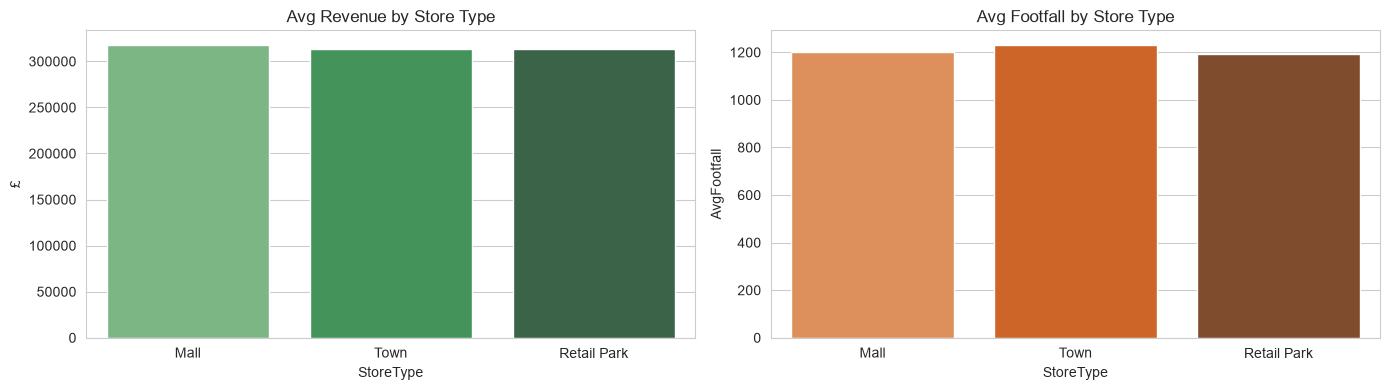

In [15]:
storetype_stats = retail_clean.groupby('StoreType').agg(
    TotalRevenue=('SalesRevenue','sum'),
    AvgRevenue=('SalesRevenue','mean'),
    AvgFootfall=('Footfall','mean'),
    AvgOnlineTraffic=('OnlineTraffic','mean'),
    AvgSatisfaction=('CustomerSatisfaction','mean'),
    N_Records=('SalesRevenue','count')
).round(2).sort_values('AvgRevenue', ascending=False)

print("=== GROUPBY 2: Revenue by Store Type ===")
print(storetype_stats)

fig, axes = plt.subplots(1, 2, figsize=(14, 4))
sns.barplot(x=storetype_stats.index, y=storetype_stats['AvgRevenue'], ax=axes[0], palette='Greens_d')
axes[0].set_title('Avg Revenue by Store Type'); axes[0].set_ylabel('£')

sns.barplot(x=storetype_stats.index, y=storetype_stats['AvgFootfall'], ax=axes[1], palette='Oranges_d')
axes[1].set_title('Avg Footfall by Store Type')
plt.tight_layout(); plt.show()

=== GROUPBY 3: Revenue by Season ===
        TotalRevenue  AvgRevenue  AvgDiscount  AvgSatisfaction  N_Records
Season                                                                   
Autumn  1.212909e+08   316686.37        19.59            74.94        383
Spring  1.210185e+08   315152.34        19.99            74.61        384
Summer  1.181592e+08   315091.16        20.43            75.23        375
Winter  1.195903e+08   312246.28        20.98            74.95        383


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\2587602311.py:13: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=season_stats.index, y=season_stats['AvgRevenue'], ax=ax, palette='Purples_d')


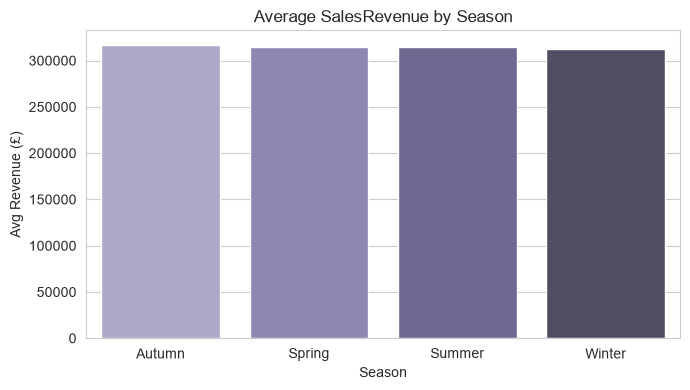

In [16]:
season_stats = retail_clean.groupby('Season').agg(
    TotalRevenue=('SalesRevenue','sum'),
    AvgRevenue=('SalesRevenue','mean'),
    AvgDiscount=('DiscountRate','mean'),
    AvgSatisfaction=('CustomerSatisfaction','mean'),
    N_Records=('SalesRevenue','count')
).round(2).sort_values('AvgRevenue', ascending=False)

print("=== GROUPBY 3: Revenue by Season ===")
print(season_stats)

fig, ax = plt.subplots(figsize=(7,4))
sns.barplot(x=season_stats.index, y=season_stats['AvgRevenue'], ax=ax, palette='Purples_d')
ax.set_title('Average SalesRevenue by Season')
ax.set_ylabel('Avg Revenue (£)')
plt.tight_layout(); plt.show()

=== GROUPBY 4: Revenue by Marketing Spend Quartile ===
                   AvgRevenue  AvgFootfall  AvgSatisfaction  N_Records
MarketingQuartile                                                     
Q1 (Low)            254081.78      1218.45            74.95        382
Q2                  308053.98      1179.91            74.41        434
Q3                  332482.35      1234.98            75.29        328
Q4 (High)           368110.27      1210.11            75.20        381


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\1864290716.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mkt_stats.index, y=mkt_stats['AvgRevenue'], ax=ax, palette='Reds_d')


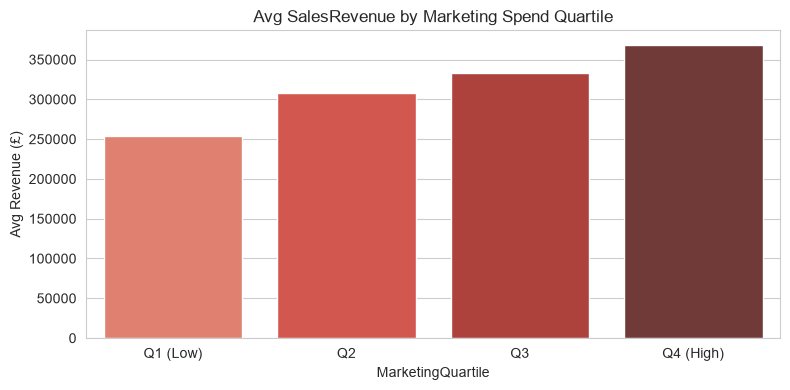

In [17]:
retail_clean['MarketingQuartile'] = pd.qcut(
    retail_clean['MarketingSpend'], q=4,
    labels=['Q1 (Low)','Q2','Q3','Q4 (High)']
)

mkt_stats = retail_clean.groupby('MarketingQuartile', observed=True).agg(
    AvgRevenue=('SalesRevenue','mean'),
    AvgFootfall=('Footfall','mean'),
    AvgSatisfaction=('CustomerSatisfaction','mean'),
    N_Records=('SalesRevenue','count')
).round(2)

print("=== GROUPBY 4: Revenue by Marketing Spend Quartile ===")
print(mkt_stats)

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=mkt_stats.index, y=mkt_stats['AvgRevenue'], ax=ax, palette='Reds_d')
ax.set_title('Avg SalesRevenue by Marketing Spend Quartile')
ax.set_ylabel('Avg Revenue (£)')
plt.tight_layout(); plt.show()

=== GROUPBY 4: Revenue by Marketing Spend Quartile ===
                   AvgRevenue  AvgFootfall  AvgSatisfaction  N_Records
MarketingQuartile                                                     
Q1 (Low)            254081.78      1218.45            74.95        382
Q2                  308053.98      1179.91            74.41        434
Q3                  332482.35      1234.98            75.29        328
Q4 (High)           368110.27      1210.11            75.20        381


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\1864290716.py:17: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(x=mkt_stats.index, y=mkt_stats['AvgRevenue'], ax=ax, palette='Reds_d')


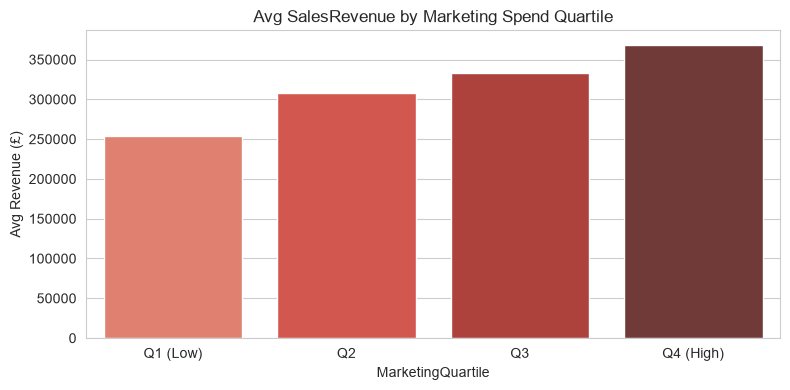

In [18]:
retail_clean['MarketingQuartile'] = pd.qcut(
    retail_clean['MarketingSpend'], q=4,
    labels=['Q1 (Low)','Q2','Q3','Q4 (High)']
)

mkt_stats = retail_clean.groupby('MarketingQuartile', observed=True).agg(
    AvgRevenue=('SalesRevenue','mean'),
    AvgFootfall=('Footfall','mean'),
    AvgSatisfaction=('CustomerSatisfaction','mean'),
    N_Records=('SalesRevenue','count')
).round(2)

print("=== GROUPBY 4: Revenue by Marketing Spend Quartile ===")
print(mkt_stats)

fig, ax = plt.subplots(figsize=(8,4))
sns.barplot(x=mkt_stats.index, y=mkt_stats['AvgRevenue'], ax=ax, palette='Reds_d')
ax.set_title('Avg SalesRevenue by Marketing Spend Quartile')
ax.set_ylabel('Avg Revenue (£)')
plt.tight_layout(); plt.show()

=== TOP 5 STORES (Total Revenue) ===
StoreID
1032    5520729.54
1059    5466663.56
1083    5312010.39
1071    5287993.85
1007    5283731.48
Name: SalesRevenue, dtype: float64

=== REVENUE BY REGION (Total) ===
Region
North    1.210960e+08
West     1.208470e+08
South    1.202820e+08
East     1.178340e+08
Name: SalesRevenue, dtype: float64


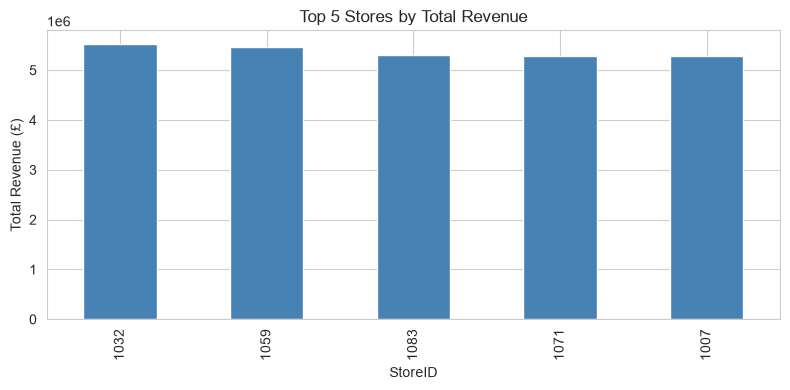

In [19]:
# Top 5 stores by TOTAL revenue (sum across their records)
top_stores = (retail_clean.groupby('StoreID')['SalesRevenue']
              .sum().sort_values(ascending=False).head(5).round(2))
print("=== TOP 5 STORES (Total Revenue) ===")
print(top_stores)

top_regions = (retail_clean.groupby('Region')['SalesRevenue']
               .sum().sort_values(ascending=False).round(2))
print("\n=== REVENUE BY REGION (Total) ===")
print(top_regions)

fig, ax = plt.subplots(figsize=(8,4))
top_stores.plot(kind='bar', ax=ax, color='steelblue')
ax.set_title('Top 5 Stores by Total Revenue')
ax.set_ylabel('Total Revenue (£)')
ax.set_xlabel('StoreID')
plt.tight_layout(); plt.show()

=== PIVOT 1: Avg SalesRevenue by Region × Season ===
Season     Autumn     Spring     Summer     Winter
Region                                            
East    319760.10  311853.71  318227.91  310481.86
North   310581.30  313924.45  315908.74  311274.68
South   321589.86  315425.87  305857.18  313260.08
West    315010.39  319362.18  320428.85  313956.38


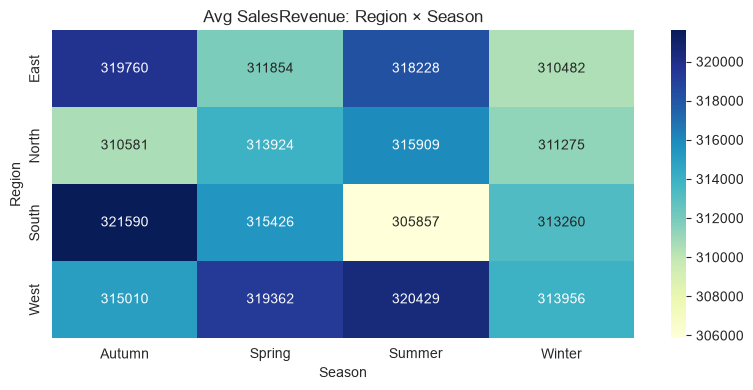

In [20]:
pivot1 = pd.pivot_table(
    retail_clean, values='SalesRevenue',
    index='Region', columns='Season',
    aggfunc='mean'
).round(2)

print("=== PIVOT 1: Avg SalesRevenue by Region × Season ===")
print(pivot1)

plt.figure(figsize=(8,4))
sns.heatmap(pivot1, annot=True, fmt='.0f', cmap='YlGnBu')
plt.title('Avg SalesRevenue: Region × Season')
plt.tight_layout(); plt.show()

=== PIVOT 2: Avg SalesRevenue by StoreType × Marketing Quartile ===
MarketingQuartile   Q1 (Low)         Q2         Q3  Q4 (High)
StoreType                                                    
Mall               248575.09  308886.27  333555.64  370108.02
Retail Park        257304.22  307314.64  332778.13  367897.91
Town               255475.93  307860.76  331355.10  365869.30


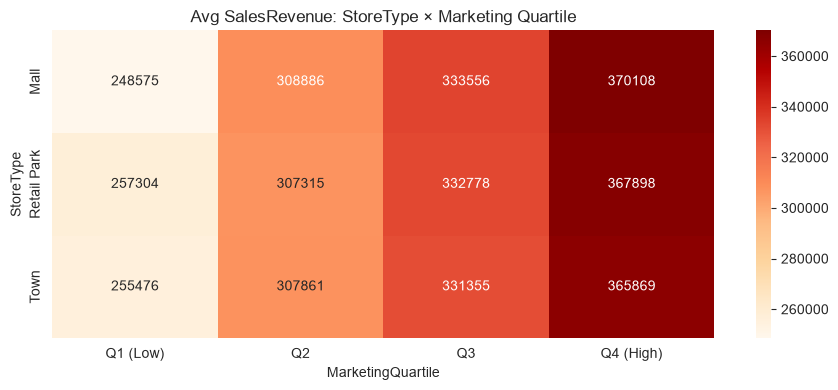

In [21]:
pivot2 = pd.pivot_table(
    retail_clean, values='SalesRevenue',
    index='StoreType', columns='MarketingQuartile',
    aggfunc='mean', observed=True
).round(2)

print("=== PIVOT 2: Avg SalesRevenue by StoreType × Marketing Quartile ===")
print(pivot2)

plt.figure(figsize=(9,4))
sns.heatmap(pivot2, annot=True, fmt='.0f', cmap='OrRd')
plt.title('Avg SalesRevenue: StoreType × Marketing Quartile')
plt.tight_layout(); plt.show()

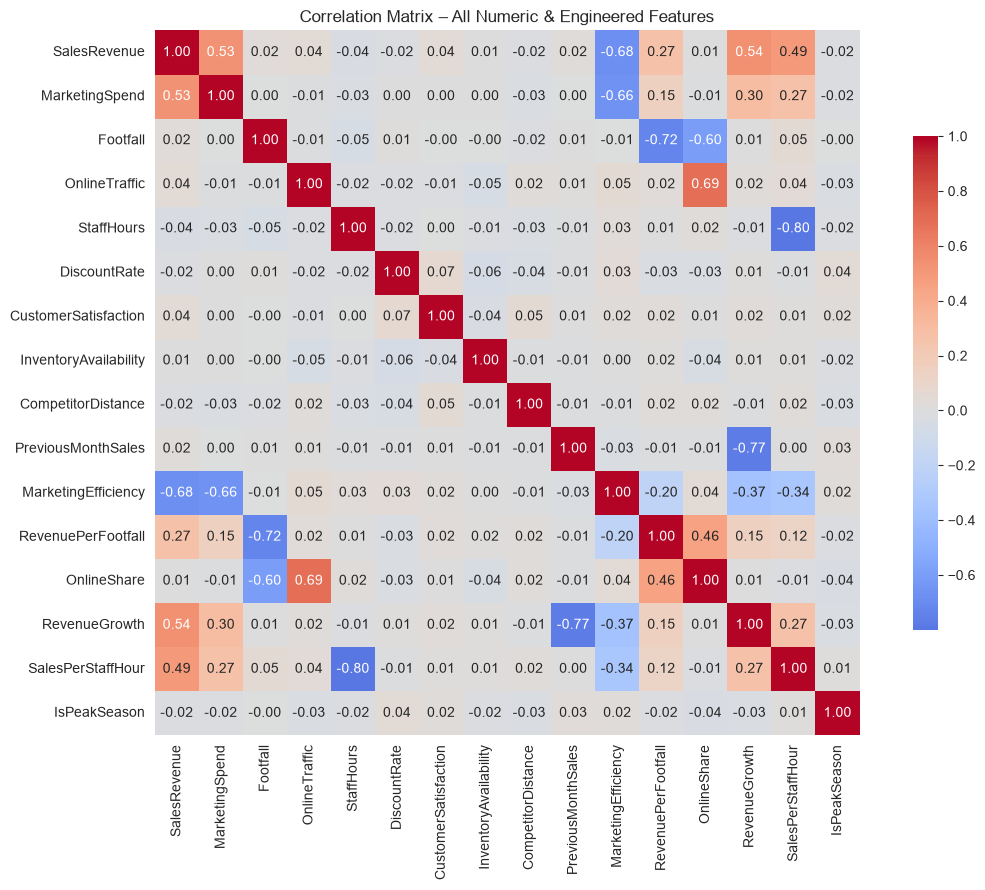


=== Correlation with SalesRevenue (sorted) ===
RevenueGrowth            0.539
MarketingSpend           0.531
SalesPerStaffHour        0.494
RevenuePerFootfall       0.275
OnlineTraffic            0.043
CustomerSatisfaction     0.042
Footfall                 0.023
PreviousMonthSales       0.023
InventoryAvailability    0.009
OnlineShare              0.007
CompetitorDistance      -0.021
DiscountRate            -0.022
IsPeakSeason            -0.023
StaffHours              -0.038
MarketingEfficiency     -0.684
Name: SalesRevenue, dtype: float64


In [22]:
corr_cols = ['SalesRevenue','MarketingSpend','Footfall','OnlineTraffic',
             'StaffHours','DiscountRate','CustomerSatisfaction',
             'InventoryAvailability','CompetitorDistance','PreviousMonthSales',
             'MarketingEfficiency','RevenuePerFootfall','OnlineShare',
             'RevenueGrowth','SalesPerStaffHour','IsPeakSeason']

corr = retail_clean[corr_cols].corr(numeric_only=True)

plt.figure(figsize=(12,9))
sns.heatmap(corr, annot=True, fmt='.2f', cmap='coolwarm', center=0,
            square=True, cbar_kws={'shrink':0.7})
plt.title('Correlation Matrix – All Numeric & Engineered Features')
plt.tight_layout(); plt.show()

print("\n=== Correlation with SalesRevenue (sorted) ===")
print(corr['SalesRevenue'].drop('SalesRevenue').sort_values(ascending=False).round(3))

In [23]:
# Exclude target and leak-prone / ID columns
feature_cols = ['MarketingSpend','Footfall','OnlineTraffic','StaffHours',
                'DiscountRate','CustomerSatisfaction','InventoryAvailability',
                'CompetitorDistance','PreviousMonthSales','IsPeakSeason']

X = retail_clean[feature_cols].copy()
y = retail_clean['SalesRevenue'].copy()

# Guard against any lingering NaN (from engineered ratios)
mask = ~(X.isnull().any(axis=1) | y.isnull())
X, y = X[mask], y[mask]

print(f"Model rows: {len(X)}")
print(f"Feature columns: {feature_cols}")

X_train, X_test, y_train, y_test = train_test_split(
    X, y, test_size=0.2, random_state=42
)
print(f"Train: {len(X_train)} | Test: {len(X_test)}")

# Scale for Linear Regression (tree models don't need it, but it's harmless)
scaler = StandardScaler().fit(X_train)
X_train_s = scaler.transform(X_train)
X_test_s  = scaler.transform(X_test)

Model rows: 1525
Feature columns: ['MarketingSpend', 'Footfall', 'OnlineTraffic', 'StaffHours', 'DiscountRate', 'CustomerSatisfaction', 'InventoryAvailability', 'CompetitorDistance', 'PreviousMonthSales', 'IsPeakSeason']
Train: 1220 | Test: 305


=== MODEL COMPARISON ===
            Model      MAE     RMSE     R2
    Random Forest  7951.78 13084.16 0.9271
    Decision Tree  8857.37 13659.76 0.9206
Linear Regression 29797.91 40526.76 0.3007


C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\3417761108.py:24: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='Model', y='RMSE', ax=axes[0], palette='Reds_d')
C:\Users\Kiero\AppData\Local\Temp\ipykernel_16548\3417761108.py:26: FutureWarning: 

Passing `palette` without assigning `hue` is deprecated and will be removed in v0.14.0. Assign the `x` variable to `hue` and set `legend=False` for the same effect.

  sns.barplot(data=res_df, x='Model', y='R2', ax=axes[1], palette='Greens_d')


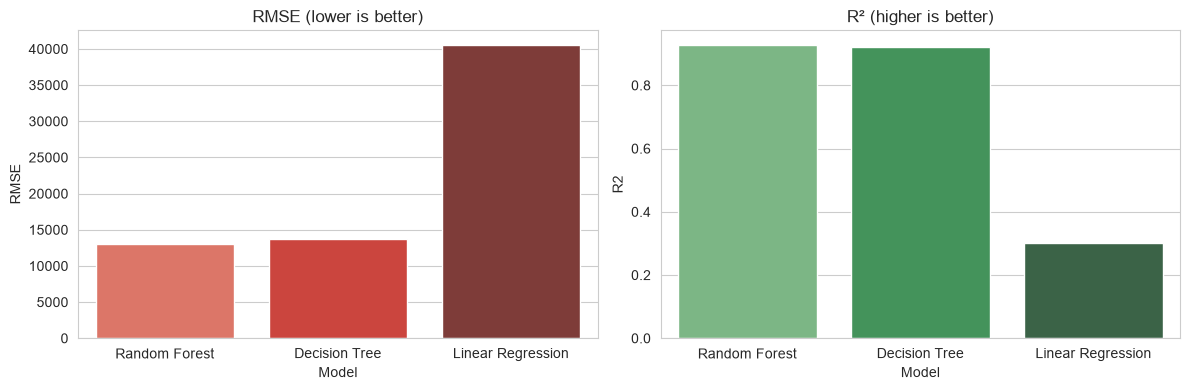

In [24]:
def evaluate(name, model, Xtr, Xte):
    model.fit(Xtr, y_train)
    pred = model.predict(Xte)
    return {
        'Model': name,
        'MAE':  round(mean_absolute_error(y_test, pred), 2),
        'RMSE': round(np.sqrt(mean_squared_error(y_test, pred)), 2),
        'R2':   round(r2_score(y_test, pred), 4)
    }

results = []
# Linear Regression (uses scaled features)
results.append(evaluate("Linear Regression", LinearRegression(), X_train_s, X_test_s))
# Decision Tree
results.append(evaluate("Decision Tree",     DecisionTreeRegressor(random_state=42, max_depth=6), X_train, X_test))
# Random Forest
results.append(evaluate("Random Forest",     RandomForestRegressor(n_estimators=200, random_state=42, max_depth=8), X_train, X_test))

res_df = pd.DataFrame(results).sort_values('R2', ascending=False)
print("=== MODEL COMPARISON ===")
print(res_df.to_string(index=False))

fig, axes = plt.subplots(1, 2, figsize=(12,4))
sns.barplot(data=res_df, x='Model', y='RMSE', ax=axes[0], palette='Reds_d')
axes[0].set_title('RMSE (lower is better)')
sns.barplot(data=res_df, x='Model', y='R2', ax=axes[1], palette='Greens_d')
axes[1].set_title('R² (higher is better)')
plt.tight_layout(); plt.show()

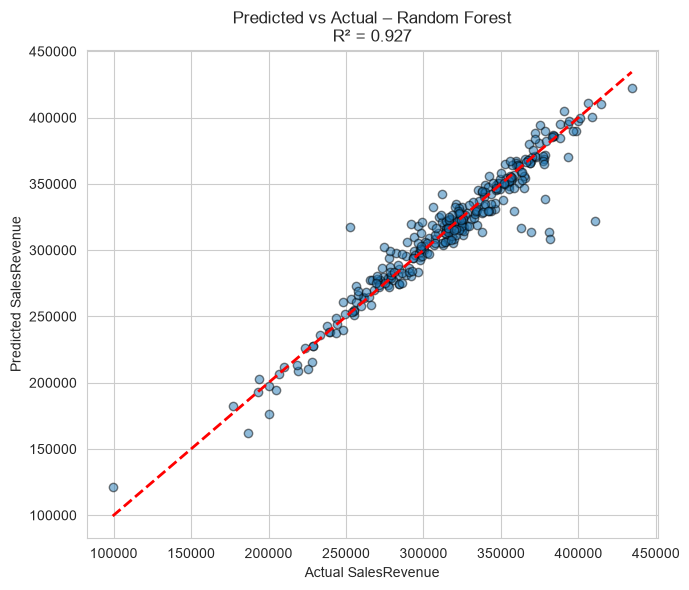

In [25]:
best_row = res_df.iloc[0]
best_name = best_row['Model']

# Re-instantiate the winner
if best_name == "Linear Regression":
    best_model = LinearRegression().fit(X_train_s, y_train)
    preds = best_model.predict(X_test_s)
elif best_name == "Decision Tree":
    best_model = DecisionTreeRegressor(random_state=42, max_depth=6).fit(X_train, y_train)
    preds = best_model.predict(X_test)
else:
    best_model = RandomForestRegressor(n_estimators=200, random_state=42, max_depth=8).fit(X_train, y_train)
    preds = best_model.predict(X_test)

plt.figure(figsize=(7,6))
plt.scatter(y_test, preds, alpha=0.5, edgecolor='k')
plt.plot([y_test.min(), y_test.max()],
         [y_test.min(), y_test.max()], 'r--', lw=2)
plt.xlabel('Actual SalesRevenue')
plt.ylabel('Predicted SalesRevenue')
plt.title(f'Predicted vs Actual – {best_name}\nR² = {best_row["R2"]:.3f}')
plt.tight_layout(); plt.show()

=== FEATURE IMPORTANCE (Random Forest) ===
MarketingSpend           0.9426
OnlineTraffic            0.0096
DiscountRate             0.0094
CustomerSatisfaction     0.0071
CompetitorDistance       0.0070
StaffHours               0.0069
Footfall                 0.0065
InventoryAvailability    0.0055
PreviousMonthSales       0.0048
IsPeakSeason             0.0005
dtype: float64


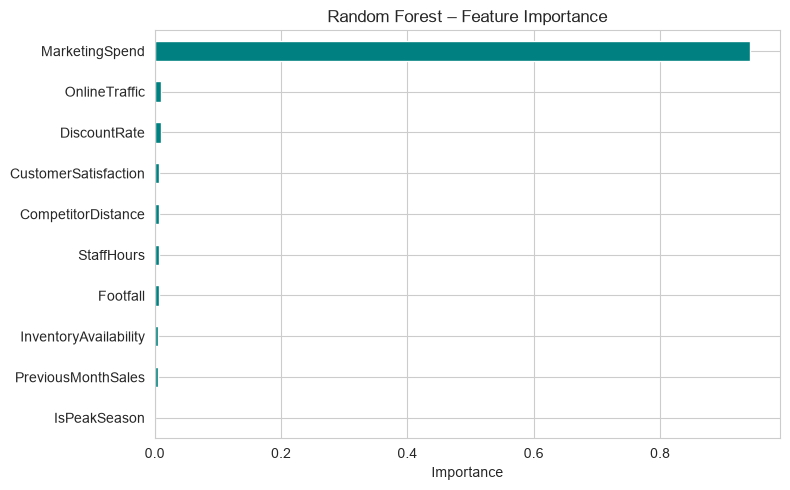

In [26]:
rf = RandomForestRegressor(n_estimators=300, random_state=42, max_depth=8).fit(X_train, y_train)

importance = pd.Series(rf.feature_importances_, index=feature_cols).sort_values(ascending=False)
print("=== FEATURE IMPORTANCE (Random Forest) ===")
print(importance.round(4))

fig, ax = plt.subplots(figsize=(8,5))
importance.plot(kind='barh', ax=ax, color='teal')
ax.invert_yaxis()
ax.set_title('Random Forest – Feature Importance')
ax.set_xlabel('Importance')
plt.tight_layout(); plt.show()

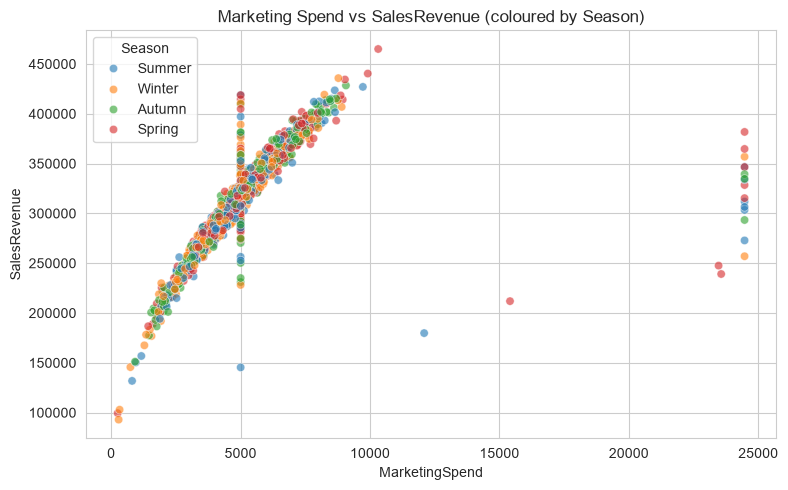

In [27]:
plt.figure(figsize=(8,5))
sns.scatterplot(data=retail_clean, x='MarketingSpend', y='SalesRevenue',
                hue='Season', alpha=0.6)
plt.title('Marketing Spend vs SalesRevenue (coloured by Season)')
plt.tight_layout(); plt.show()

In [28]:
retail_clean.to_csv('retail_clean_with_models_ready.csv', index=False)
print(" Saved final cleaned dataset with engineered features.")
print("\nHeadline numbers for the report:")
print(f"Best model: {best_name}")
print(f"R² = {best_row['R2']:.3f}   RMSE = {best_row['RMSE']:.2f}   MAE = {best_row['MAE']:.2f}")
print("\nTop 3 drivers (Random Forest):")
print(importance.head(3).round(3).to_string())

 Saved final cleaned dataset with engineered features.

Headline numbers for the report:
Best model: Random Forest
R² = 0.927   RMSE = 13084.16   MAE = 7951.78

Top 3 drivers (Random Forest):
MarketingSpend    0.943
OnlineTraffic     0.010
DiscountRate      0.009
